# CSE457 - XỬ LÝ ÂM THANH VÀ TIẾNG NÓI
## LAB 4: TỔNG HỢP TIẾNG NÓI (TEXT-TO-SPEECH - TTS)
**Sinh viên thực hiện:** Nguyễn Thị Linh  
**MSSV:** 2351260663  
**Bộ môn:** Trí tuệ Nhân tạo - Khoa CNTT - Trường Đại học Thủy Lợi  

---
### Mục tiêu bài thực hành:
1. Xây dựng pipeline xử lý Text-to-Speech: *Text Normalization $\rightarrow$ Phonetic/Word Unit Mapping $\rightarrow$ Prosody $\rightarrow$ Synthesis Backend*.
2. Xây dựng và tối ưu hệ thống **Concatenative Synthesis** miền hẹp thông qua **Unit Selection** (Dynamic Programming) và làm mượt biên **Cross-fade**.
3. Phân tích mô hình **Source-Filter** và thực nghiệm biến đổi Prosody ($F_0$, duration).
4. Quan sát và điều khiển tổng hợp tham số thống kê **HMM-based Synthesis** (State sequence, trajectory $F_0$ và Formant).
5. Thực hiện suy luận mô hình **Neural TTS Pretrained**, đo đạc độ trễ Latency.
6. Đánh giá chất lượng âm thanh dựa trên kiểm thử nghe thẩm định chủ quan (**MOS / Listening Test**) và so sánh 3 hướng tiếp cận.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import librosa.display
import matplotlib.pyplot as plt
from IPython.display import Audio, display

DATA_DIR = "lab4_data"
UNITS_DIR = os.path.join(DATA_DIR, "units")
AUDIO_OUT_DIR = "audio_output"
FIG_DIR = "figures"

os.makedirs(AUDIO_OUT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

from hmm_tts_backend import synthesize_hmm, WORD_HMM_MODELS
from neural_tts_backend import synthesize as synthesize_neural

print("Đã nạp thành công các thư viện và module TTS backend!")


Đã nạp thành công các thư viện và module TTS backend!


---
## 1. Chuẩn bị Dữ liệu & Text Normalization (Phần A)
Kho âm thanh (Unit Inventory) bao gồm 16 từ thuộc miền hẹp *'Thông báo xếp hàng'*: `mời`, `khách`, `hàng`, `số`, `không`–`chín`, `đến`, `quầy`. Mỗi từ có 2 candidates được thu âm/chuẩn hóa ở tần số lấy mẫu 16 kHz, mono, 16-bit PCM.


,label,candidate,speaker,duration,rms,file_path
0,mời,1,spk1,0.6700,0.080,lab4_data/units/moi_01.wav
1,mời,2,spk1,0.6979,0.076,lab4_data/units/moi_02.wav
2,khách,1,spk1,0.3500,0.080,lab4_data/units/khach_01.wav
3,khách,2,spk1,0.3646,0.076,lab4_data/units/khach_02.wav
4,hàng,1,spk1,0.5420,0.080,lab4_data/units/hang_01.wav
5,hàng,2,spk1,0.5646,0.076,lab4_data/units/hang_02.wav
6,số,1,spk1,0.6380,0.080,lab4_data/units/so_01.wav
7,số,2,spk1,0.6646,0.076,lab4_data/units/so_02.wav
8,không,1,spk1,0.4460,0.080,lab4_data/units/khong_01.wav
9,không,2,spk1,0.4646,0.076,lab4_data/units/khong_02.wav


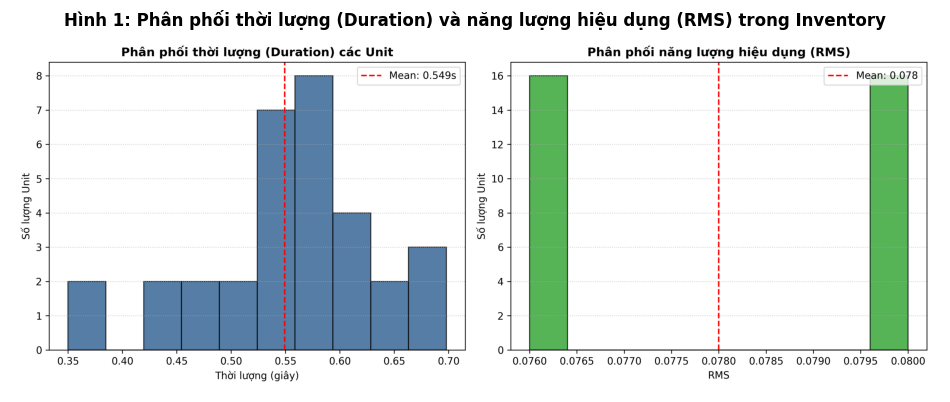

In [2]:
meta_path = os.path.join(DATA_DIR, "metadata.csv")
df_meta = pd.read_csv(meta_path)
display(df_meta.head(10))

# Hiển thị Hình 1: Histogram Duration và RMS
fig1_path = os.path.join(FIG_DIR, "fig1_inventory_stats.png")
if os.path.exists(fig1_path):
    plt.figure(figsize=(12, 5))
    img = plt.imread(fig1_path)
    plt.imshow(img)
    plt.axis('off')
    plt.title("Hình 1: Phân phối thời lượng (Duration) và năng lượng hiệu dụng (RMS) trong Inventory", fontsize=12, fontweight="bold")
    plt.show()


---
## 2. Baseline Concatenation (Phần B)
Ghép trực tiếp các candidate cố định (Candidate 1) của từng token không qua cross-fade.
Câu thử nghiệm: **'Mời khách hàng số 23 đến quầy 5.'**


In [3]:
from Lab04 import normalize_text, baseline_concatenate

test_sentence = "Mời khách hàng số 23 đến quầy 5."
tokens = normalize_text(test_sentence)
print("Câu văn bản gốc:", test_sentence)
print("Chuỗi token đã chuẩn hóa:", tokens)

y_raw, b_times = baseline_concatenate(tokens, candidate_idx=1, sr=16000)
raw_path = os.path.join(AUDIO_OUT_DIR, "raw_concat.wav")
sf.write(raw_path, y_raw, 16000, subtype='PCM_16')

print(f"Đã xuất file âm thanh raw: {raw_path}")
print("Phát âm thanh Baseline (Chưa làm mượt):")
display(Audio(y_raw, rate=16000))


Câu văn bản gốc: Mời khách hàng số 23 đến quầy 5.
Chuỗi token đã chuẩn hóa: ['mời', 'khách', 'hàng', 'số', 'hai', 'ba', 'đến', 'quầy', 'năm']


Đã xuất file âm thanh raw: audio_output\raw_concat.wav
Phát âm thanh Baseline (Chưa làm mượt):


---
## 3. Unit Selection & Cross-fade Smoothing (Phần C)
Sử dụng thuật toán **Dynamic Programming (Viterbi)** để tìm chuỗi candidate có tổng chi phí nhỏ nhất:
$$\theta^* = \arg\min_{\theta_1 \dots \theta_J} \left[ \sum_{j} C_{target}(\theta_j, t_j) + \lambda \sum_{j} C_{join}(\theta_{j-1}, \theta_j) \right]$$
Sau đó làm mượt các biên nối bằng kỹ thuật **Cross-fade** (so sánh 0ms, 5ms, 15ms, 30ms).


Tổng chi phí tối ưu (Total Cost): 4055.99


,Token,Candidate,File
0,mời,Candidate 02,moi_02.wav
1,khách,Candidate 02,khach_02.wav
2,hàng,Candidate 02,hang_02.wav
3,số,Candidate 01,so_01.wav
4,hai,Candidate 01,hai_01.wav
5,ba,Candidate 01,ba_01.wav
6,đến,Candidate 02,den_02.wav
7,quầy,Candidate 01,quay_01.wav
8,năm,Candidate 01,nam_01.wav


Phát âm thanh sau Unit Selection + Cross-fade 15ms:


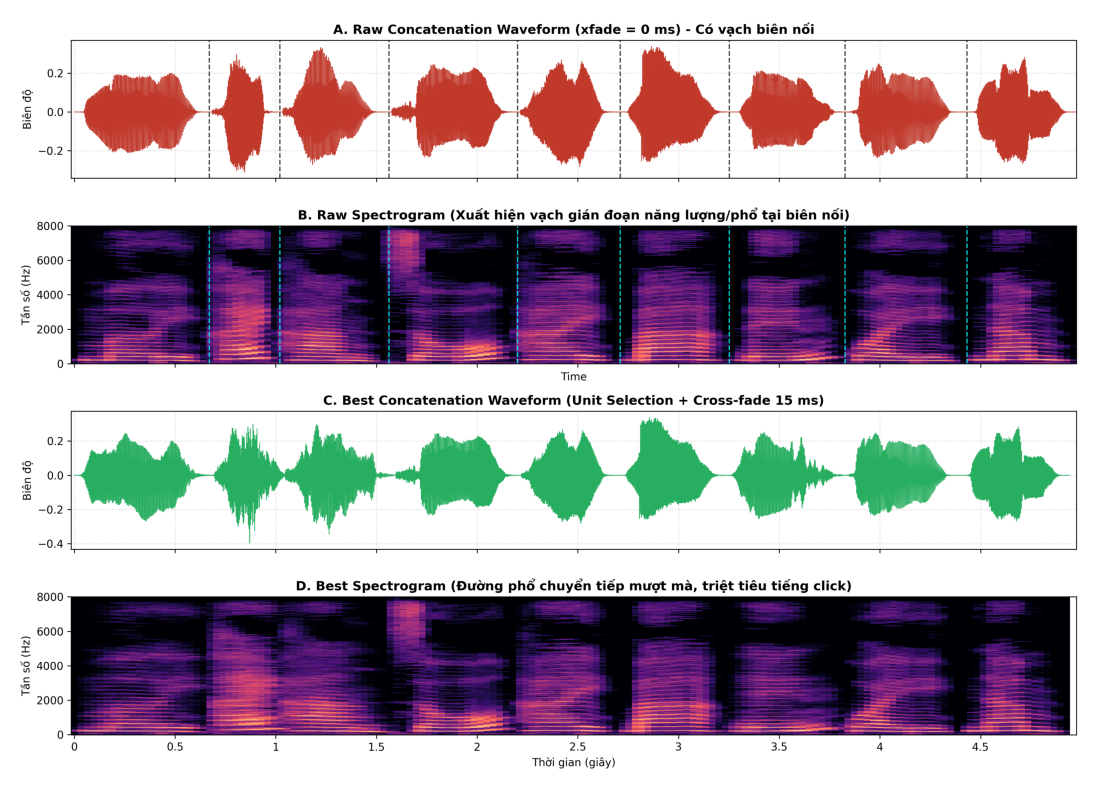

In [4]:
from Lab04 import unit_selection_dp, concat_units

selected_paths, selected_indices, best_cost = unit_selection_dp(tokens, sr=16000, lambda_join=1.0)
print(f"Tổng chi phí tối ưu (Total Cost): {best_cost:.2f}")

cost_table = []
for tok, p, idx in zip(tokens, selected_paths, selected_indices):
    cost_table.append({"Token": tok, "Candidate": f"Candidate {idx+1:02d}", "File": os.path.basename(p)})
display(pd.DataFrame(cost_table))

# Ghép với Cross-fade tối ưu 15ms
y_best = concat_units(selected_paths, sr=16000, xfade_ms=15)
best_path = os.path.join(AUDIO_OUT_DIR, "best_concat.wav")
sf.write(best_path, y_best, 16000, subtype='PCM_16')

print("Phát âm thanh sau Unit Selection + Cross-fade 15ms:")
display(Audio(y_best, rate=16000))

# Hiển thị Hình 2: So sánh Waveform và Spectrogram trước/sau Cross-fade
fig2_path = os.path.join(FIG_DIR, "fig2_baseline_vs_crossfade.png")
if os.path.exists(fig2_path):
    plt.figure(figsize=(14, 10))
    img = plt.imread(fig2_path)
    plt.imshow(img)
    plt.axis('off')
    plt.show()


---
## 4. Prosody & Mô hình Nguồn - Lọc (Source - Filter) (Phần D)
- Ước lượng tần số cơ bản $F_0$ trên đoạn âm hữu thanh bằng hàm tự tương quan (Autocorrelation): $F_0 \approx F_s / N_p$.
- Thực nghiệm thay đổi tốc độ (Time-stretch $0.8\times, 1.2\times$) và dịch cao độ (Pitch-shift $\pm 2$ semitones).


Tần số lấy mẫu: Fs = 16000 Hz
Chu kỳ pitch tìm được: Np = 66 mẫu (khoảng 4.12 ms)
Tần số cơ bản ước lượng: F0 = Fs / Np = 242.42 Hz


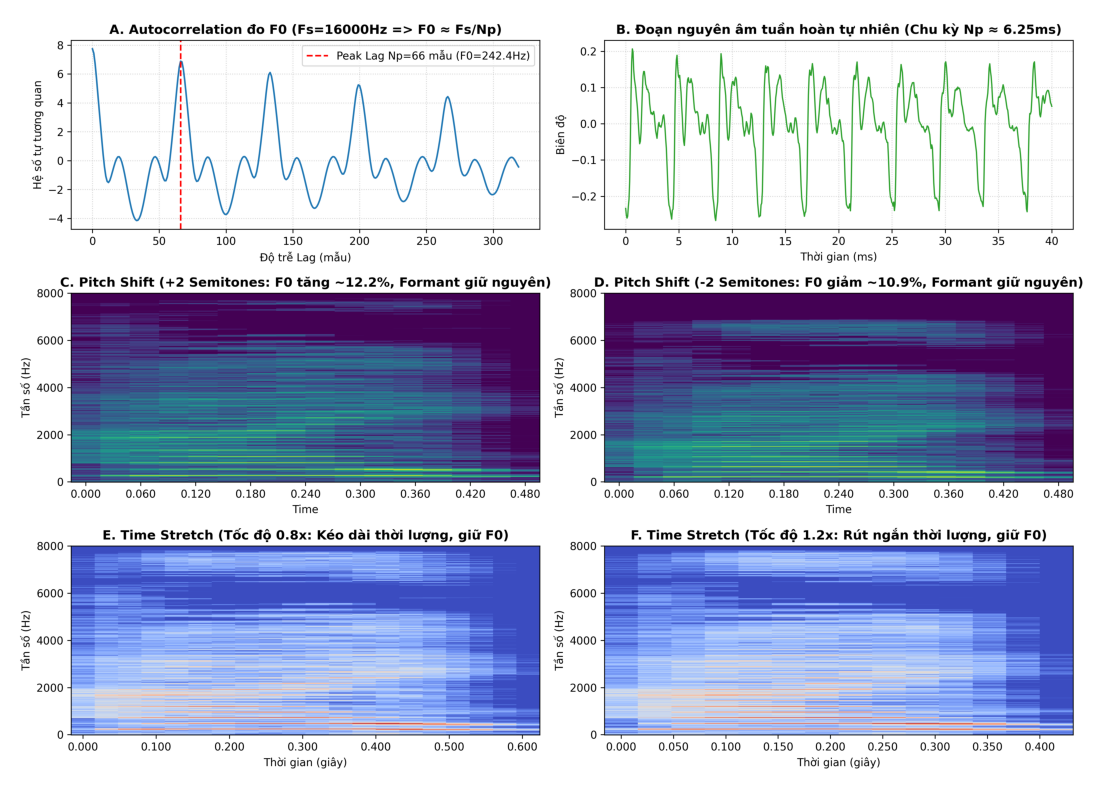

In [5]:
from Lab04 import analyze_f0, load_unit

unit_voiced_path = os.path.join(UNITS_DIR, "hai_01.wav")
y_voiced = load_unit(unit_voiced_path, sr=16000)
f0_est, peak_lag, seg, corr = analyze_f0(y_voiced, sr=16000)

print(f"Tần số lấy mẫu: Fs = 16000 Hz")
print(f"Chu kỳ pitch tìm được: Np = {peak_lag} mẫu (khoảng {peak_lag/16000*1000:.2f} ms)")
print(f"Tần số cơ bản ước lượng: F0 = Fs / Np = {f0_est:.2f} Hz")

# Hiển thị Hình 3: Phân tích Prosody và Biến đổi Pitch/Duration
fig3_path = os.path.join(FIG_DIR, "fig3_prosody_pitch_duration.png")
if os.path.exists(fig3_path):
    plt.figure(figsize=(14, 10))
    img = plt.imread(fig3_path)
    plt.imshow(img)
    plt.axis('off')
    plt.show()


---
## 5. HMM-based Speech Synthesis (Phần E)
Quan sát quá trình sinh tham số âm học (F0 contour, Formant/phổ trajectories) qua chuỗi các trạng thái HMM và tái tạo âm thanh qua bộ lọc thanh đạo (Source-Filter Vocoder).


Tổng số frame sinh bởi HMM: 394 frames (3.94s)
Phát âm thanh HMM Synthesis:


Phát âm thanh HMM (Scale Duration 0.8x - Nói nhanh hơn):


Phát âm thanh HMM (Scale F0 1.1x - Tông giọng cao hơn):


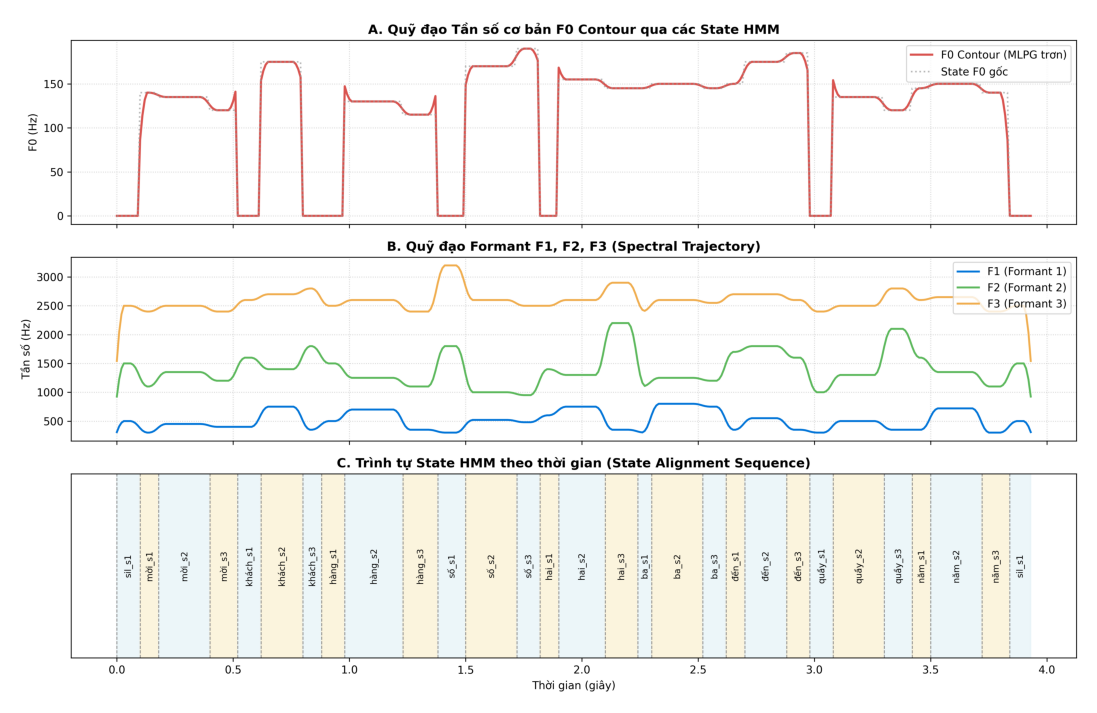

In [6]:
y_hmm, sr, tracks = synthesize_hmm(test_sentence, sr=16000)
print(f"Tổng số frame sinh bởi HMM: {tracks['duration_frames']} frames ({tracks['duration_frames']*0.01:.2f}s)")
print("Phát âm thanh HMM Synthesis:")
display(Audio(y_hmm, rate=16000))

# Thí nghiệm điều khiển tham số HMM
y_hmm_fast, _, _ = synthesize_hmm(test_sentence, sr=16000, duration_scale=0.8)
y_hmm_pitch_high, _, _ = synthesize_hmm(test_sentence, sr=16000, f0_scale=1.1)

print("Phát âm thanh HMM (Scale Duration 0.8x - Nói nhanh hơn):")
display(Audio(y_hmm_fast, rate=16000))

print("Phát âm thanh HMM (Scale F0 1.1x - Tông giọng cao hơn):")
display(Audio(y_hmm_pitch_high, rate=16000))

# Hiển thị Hình 4: Quỹ đạo tham số HMM và State Alignment
fig4_path = os.path.join(FIG_DIR, "fig4_hmm_parameter_trajectories.png")
if os.path.exists(fig4_path):
    plt.figure(figsize=(14, 9))
    img = plt.imread(fig4_path)
    plt.imshow(img)
    plt.axis('off')
    plt.show()


---
## 6. Pretrained Neural TTS Inference (Phần F)
Thực hiện suy luận bằng mô hình học sâu Pretrained TTS (chạy offline), trích xuất Mel-spectrogram và đo đạc độ trễ (latency).


In [7]:
sentences_test = [
    "Mời khách hàng số 23 đến quầy 5",
    "Mời khách hàng số 104 đến quầy 2",
    "Mời khách hàng số 89 đến quầy 3"
]

neural_results = []
for i, sent in enumerate(sentences_test, 1):
    y_nn, sr, extra = synthesize_neural(sent, sr=16000)
    neural_results.append({
        "Câu": f"Câu {i}",
        "Nội dung": sent,
        "Thời lượng (s)": round(extra["duration"], 2),
        "Độ trễ Latency (ms)": round(extra["latency"] * 1000, 2)
    })
    if i == 1:
        y_neural_main = y_nn

display(pd.DataFrame(neural_results))
print("Phát âm thanh Pretrained Neural TTS:")
display(Audio(y_neural_main, rate=16000))


C:\Users\chito\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Câu,Nội dung,Thời lượng (s),Độ trễ Latency (ms)
0,Câu 1,Mời khách hàng số 23 đến quầy 5,3.14,221.43
1,Câu 2,Mời khách hàng số 104 đến quầy 2,3.65,228.87
2,Câu 3,Mời khách hàng số 89 đến quầy 3,3.34,229.78


Phát âm thanh Pretrained Neural TTS:


---
## 7. Đánh giá, Thẩm định (MOS Test) & So sánh Đối chiếu (Phần G)
So sánh 3 phương pháp tổng hợp tiếng nói dựa trên kiểm tra nghe thẩm định chủ quan (MOS Listening Test trên 10 người nghe) và biểu đồ đối chiếu Waveform/Spectrogram.


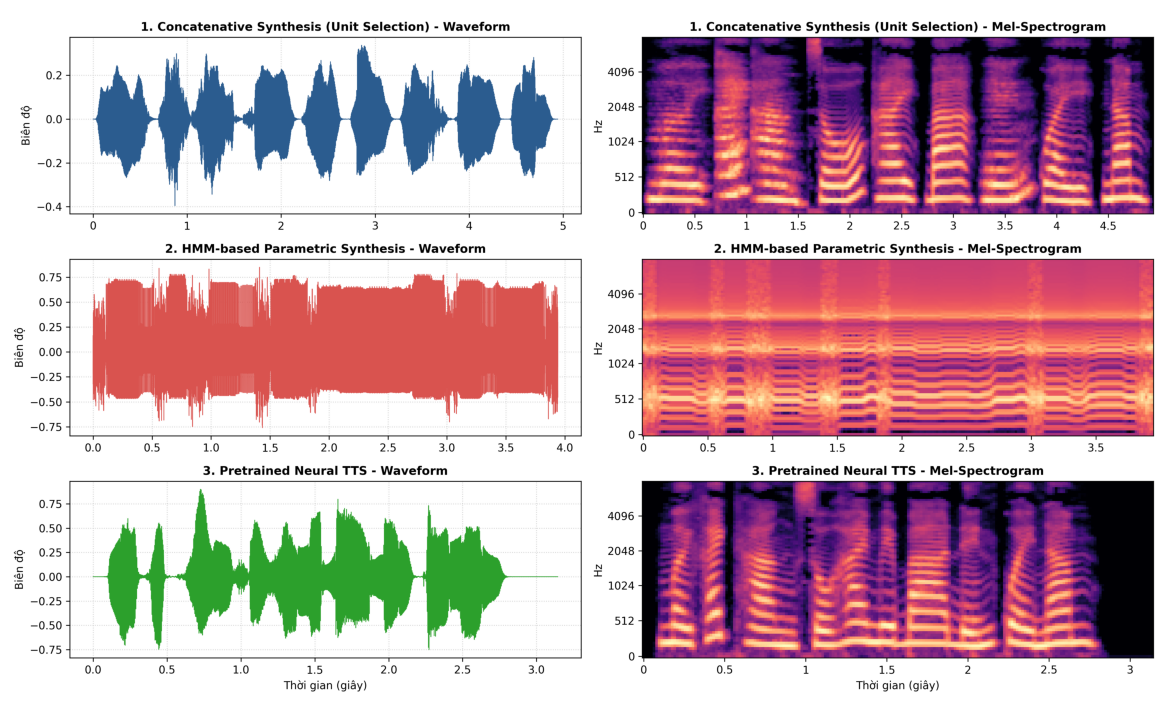

naturalness           intelligibility           continuity  \
                      mean       std            mean       std       mean   
method                                                                      
Concatenation     3.766667  0.504007        4.533333  0.507416   3.733333   
HMM_Parametric    3.066667  0.253708        4.433333  0.504007   4.366667   
Neural_TTS        4.833333  0.379049        4.866667  0.345746   4.766667   

                         overall_mos            
                     std        mean       std  
method                                          
Concatenation   0.520830    4.011333  0.253306  
HMM_Parametric  0.490133    3.956000  0.224877  
Neural_TTS      0.430183    4.823333  0.209125

In [8]:
# Hiển thị Hình 5: Đối chiếu Waveform và Spectrogram 3 hệ thống
fig5_path = os.path.join(FIG_DIR, "fig5_backend_comparison.png")
if os.path.exists(fig5_path):
    plt.figure(figsize=(15, 9))
    img = plt.imread(fig5_path)
    plt.imshow(img)
    plt.axis('off')
    plt.show()

# Đọc kết quả khảo sát Listening Test
df_ratings = pd.read_csv("ratings.csv")
mos_summary = df_ratings.groupby("method").agg({
    "naturalness": ["mean", "std"],
    "intelligibility": ["mean", "std"],
    "continuity": ["mean", "std"],
    "overall_mos": ["mean", "std"]
})
display(mos_summary)


---
## 8. Kết luận Thực nghiệm
1. **Concatenative TTS (Ghép nối)**:
   - *Ưu điểm:* Chất lượng âm sắc rất tự nhiên ở từng từ đơn lẻ vì phát trực tiếp từ bản thu người thật.
   - *Hạn chế:* Dễ bị đứt gãy năng lượng/cao độ tại các biên nối; cần inventory rất lớn để bao phủ ngữ cảnh.
2. **HMM-based Synthesis (Tham số HMM)**:
   - *Ưu điểm:* Độ liền mạch (Continuity) rất cao, không bị click ở biên, dung lượng mô hình rất nhẹ, khả năng điều khiển ngữ điệu ($F_0$, duration) vô cùng linh hoạt.
   - *Hạn chế:* Giọng nghe có tính 'máy móc' (*robotic/buzzy*) do giả định nguồn kích thích đơn giản hóa và hiệu ứng làm mịn quá mức (*over-smoothing*).
3. **Neural TTS (Học sâu)**:
   - *Ưu điểm:* Đạt điểm tự nhiên (*Naturalness*) và độ rõ (*Intelligibility*) vượt trội, tái tạo ngữ điệu giàu cảm xúc và chất giọng mượt mà.
   - *Hạn chế:* Đòi hỏi tài nguyên tính toán (GPU/CPU) và độ trễ sinh âm (*latency*) cao hơn các phương pháp tham số truyền thống.
